# **Pneumonia Chest X-ray Classification**
### DataMites Project Mentoring PR-0019 | PRAICP-1012
### Domain: Healthcare | Task: Binary Image Classification (Normal vs Pneumonia)

---
## **Introduction**

Pneumonia is a lung infection that fills the air sacs with fluid or pus. A **chest X-ray** is one of the most common ways doctors diagnose it, but reading X-rays takes a trained radiologist and time. A model that can screen X-rays automatically can help doctors prioritise urgent cases and reduce reading workload, especially where specialists are scarce.

**Business case (from problem statement):** Develop a machine learning model that can classify the X-ray image of a chest.

**Objectives:**
1. Create a model that can detect Pneumonia from chest X-ray images.
2. Compare a CNN built from scratch against a pre-trained (transfer learning) model.
3. Evaluate with medical-relevant metrics (recall, precision, F1, ROC-AUC), not just accuracy.
4. Save the best model and provide a function that predicts on a new X-ray.
5. Document the challenges faced and possible future enhancements.

**Dataset:** Two directories of chest X-ray images, one with Pneumonia patients and one without (`Chest-Xray-2.zip`).

**Workflow followed (roadmap):**
1. Setup and Imports
2. Data Collection
3. Basic Checks
4. Exploratory Data Analysis (EDA)
5. Data Preprocessing (split, class weights, input pipeline, augmentation)
6. Model 1: CNN from scratch
7. Model 2: Transfer Learning (MobileNetV2)
8. Model Comparison
9. Final Model Selection and Save
10. Predict on a new X-ray
11. Conclusion, Challenges Faced and Future Enhancements

# **Setup and Imports**

**What this section does:** Imports every library in logical groups: core data handling (numpy, pandas), visualisation (matplotlib, seaborn), deep learning (TensorFlow / Keras) and evaluation metrics (scikit-learn). Seeds are fixed for numpy, Python and TensorFlow so results are reproducible. Doing all imports in one place makes dependencies explicit.

In [4]:
# Core libraries
import os
import random
import zipfile
import urllib.request
import warnings
import numpy as np
import pandas as pd
from PIL import Image
warnings.filterwarnings('ignore')

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')
%matplotlib inline

# Deep learning
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Splitting, class weights and metrics
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, classification_report)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow version:', tf.__version__)
print('GPU available     :', len(tf.config.list_physical_devices('GPU')) > 0)

TensorFlow version: 2.21.0
GPU available     : False


**Configuration:** All adjustable settings live in one cell so they are easy to change. Images are resized to 160x160 (a size supported by the pre-trained MobileNetV2 weights used later).

In [5]:
DATA_URL  = "https://d3ilbtxij3aepc.cloudfront.net/projects/CNN-PROJECT-7-11/Chest-Xray-2.zip"
ZIP_PATH  = "Chest-Xray-2.zip"
DATA_DIR  = "chest_xray_data"
OUTPUT_DIR = "outputs"

IMG_SIZE   = (160, 160)   # every image is resized to this
BATCH_SIZE = 32
EPOCHS_CNN = 15           # max epochs for the CNN (early stopping may stop sooner)
EPOCHS_TL  = 8            # max epochs for transfer learning, stage 1
EPOCHS_FT  = 5            # max epochs for transfer learning, stage 2 (fine-tuning)

CLASS_NAMES = ['Normal', 'Pneumonia']    # label 0 = Normal, label 1 = Pneumonia
IMAGE_EXTS  = ('.jpg', '.jpeg', '.png', '.bmp')

os.makedirs(OUTPUT_DIR, exist_ok=True)

# **Data Collection**

**What this section does:** Downloads the dataset zip from the link in the problem statement and extracts it. The code checks whether the files already exist, so re-running the notebook does not download again. The folder tree is printed so you can confirm the structure (two class folders, possibly inside train/test sub-folders).

**Why this matters:** The labels come from the folder names, so we must see the real structure before trusting the labelling in the next step.

In [3]:
# Download once
if not os.path.exists(ZIP_PATH):
    print('Downloading dataset ...')
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)

# Extract once
if not os.path.isdir(DATA_DIR):
    print('Extracting ...')
    with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
        zf.extractall(DATA_DIR)
print('Dataset ready.')

# Show the folder structure (up to 3 levels) with the number of images in each folder
for folder, subdirs, files in os.walk(DATA_DIR):
    if '__MACOSX' in folder:
        continue
    depth = folder.replace(DATA_DIR, '').count(os.sep)
    if depth <= 3:
        n_img = sum(f.lower().endswith(IMAGE_EXTS) for f in files)
        print('  ' * depth + f'{os.path.basename(folder)}/   ({n_img} images)')

Extracting ...
Dataset ready.
chest_xray_data/   (0 images)
  chest_xray/   (0 images)
    train/   (0 images)
      NORMAL/   (1341 images)
      PNEUMONIA/   (3875 images)
    val/   (0 images)
      NORMAL/   (8 images)
      PNEUMONIA/   (8 images)
    test/   (0 images)
      NORMAL/   (234 images)
      PNEUMONIA/   (390 images)


# **Basic Checks**

**What this section does:** Builds a DataFrame with one row per image: its file path, its class label and the folder it came from. The label is read from the folder names (a folder called *Normal*, *Healthy* or *Negative*, or starting with *No/Non*, means label 0; a folder with *Pneumonia* in its name means label 1).

**Why a DataFrame:** It lets us use the same inspection tools as tabular data: counts, duplicates and a clean train/validation/test split.

**Check carefully:** The table printed below shows which folder was given which label. If a folder is labelled wrongly, edit `label_from_folder` before continuing.

In [6]:
def label_from_folder(name):
    # Convert a folder name to a label: 0 = Normal, 1 = Pneumonia, None = unknown
    name = name.lower()
    if any(k in name for k in ['normal', 'healthy', 'negative']) or name.startswith(('no', 'non', 'not')):
        return 0
    if 'pneum' in name or 'positive' in name:
        return 1
    return None

def infer_label(rel_folder):
    # Look from the deepest folder upwards until a folder name gives a label
    for part in reversed(rel_folder.split(os.sep)):
        lab = label_from_folder(part)
        if lab is not None:
            return lab
    return None

records = []
for folder, _, files in os.walk(DATA_DIR):
    if '__MACOSX' in folder:                 # junk folder created by macOS zips
        continue
    rel = os.path.relpath(folder, DATA_DIR)
    for f in files:
        if f.lower().endswith(IMAGE_EXTS) and not f.startswith('._'):
            records.append({'path': os.path.join(folder, f),
                            'folder': rel,
                            'label': infer_label(rel)})

df = pd.DataFrame(records)
print('Images found           :', len(df))
print('Images with no label   :', df['label'].isna().sum())
df = df.dropna(subset=['label']).reset_index(drop=True)
df['label'] = df['label'].astype(int)
df['class_name'] = df['label'].map(dict(enumerate(CLASS_NAMES)))

# Which folder got which label? (verify this table!)
df.groupby(['folder', 'class_name']).size().rename('images').reset_index()

Images found           : 5856
Images with no label   : 0


,folder,class_name,images
0,chest_xray/test/NORMAL,Normal,234
1,chest_xray/test/PNEUMONIA,Pneumonia,390
2,chest_xray/train/NORMAL,Normal,1341
3,chest_xray/train/PNEUMONIA,Pneumonia,3875
4,chest_xray/val/NORMAL,Normal,8
5,chest_xray/val/PNEUMONIA,Pneumonia,8


In [7]:
df.head()

,path,folder,label,class_name
0,chest_xray_data/chest_xray/train/NORMAL/IM-042...,chest_xray/train/NORMAL,0,Normal
1,chest_xray_data/chest_xray/train/NORMAL/NORMAL...,chest_xray/train/NORMAL,0,Normal
2,chest_xray_data/chest_xray/train/NORMAL/IM-019...,chest_xray/train/NORMAL,0,Normal
3,chest_xray_data/chest_xray/train/NORMAL/NORMAL...,chest_xray/train/NORMAL,0,Normal
4,chest_xray_data/chest_xray/train/NORMAL/NORMAL...,chest_xray/train/NORMAL,0,Normal


In [8]:
print('Shape            :', df.shape)
print('Duplicate paths  :', df['path'].duplicated().sum())
print('Classes present  :', sorted(df['class_name'].unique()))
assert df['label'].nunique() == 2, 'Both classes must be present - check the folder names / labelling above.'
df['class_name'].value_counts()

Shape            : (5856, 4)
Duplicate paths  : 0
Classes present  : ['Normal', 'Pneumonia']


,count
class_name,
Pneumonia,4273
Normal,1583


# **Exploratory Data Analysis (EDA)**

**What this section does:** Looks at the images before modelling: how balanced the classes are, what the X-rays look like, how different the image sizes are, and whether brightness differs between classes.

**Why it matters:** Class imbalance changes how we train and how we judge the model. Different image sizes confirm that resizing is needed. Looking at the images is a sanity check that the labels make sense.

### Class distribution

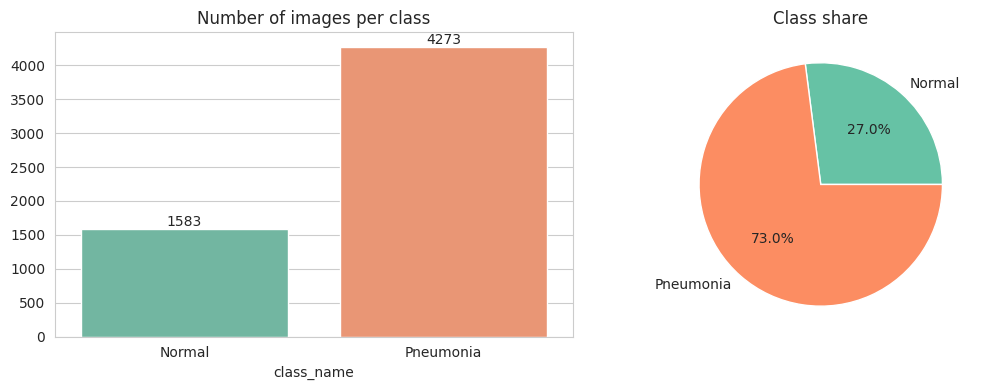

Imbalance ratio (majority : minority) = 2.70 : 1


In [9]:
counts = df['class_name'].value_counts().reindex(CLASS_NAMES)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(x=counts.index, y=counts.values, palette='Set2', ax=ax[0])
for i, c in enumerate(counts.values):
    ax[0].text(i, c, str(c), ha='center', va='bottom')
ax[0].set_title('Number of images per class')
ax[1].pie(counts.values, labels=counts.index, autopct='%1.1f%%', colors=sns.color_palette('Set2'))
ax[1].set_title('Class share')
plt.tight_layout()
plt.show()

print(f'Imbalance ratio (majority : minority) = {counts.max() / counts.min():.2f} : 1')

**Insight:** If one class is clearly larger, a model can score a high accuracy just by favouring it. This is why we use **class weights** during training and judge the model with **recall, precision, F1 and ROC-AUC** rather than accuracy alone.

### Sample X-rays

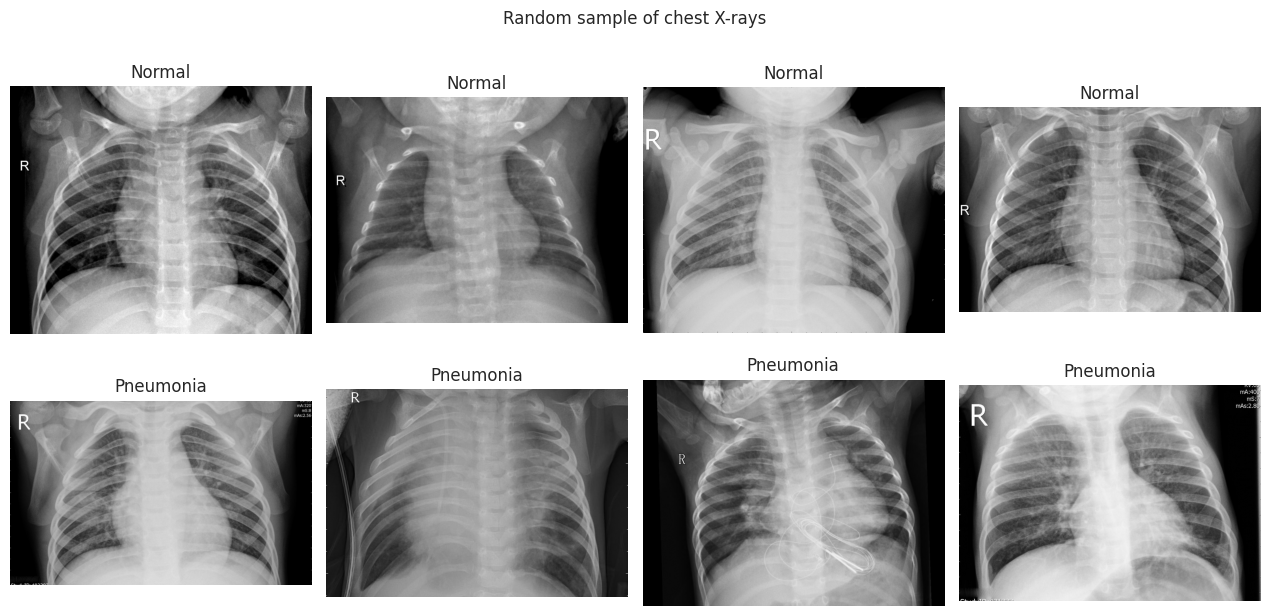

In [10]:
n = 4
fig, axes = plt.subplots(2, n, figsize=(3.2 * n, 6.5))
for row, cls in enumerate([0, 1]):
    sample = df[df['label'] == cls].sample(n, random_state=SEED)
    for col, p in enumerate(sample['path']):
        axes[row, col].imshow(Image.open(p).convert('L'), cmap='gray')
        axes[row, col].set_title(CLASS_NAMES[cls])
        axes[row, col].axis('off')
plt.suptitle('Random sample of chest X-rays', y=1.0)
plt.tight_layout()
plt.show()

**Insight:** Pneumonia X-rays usually show cloudy white patches (opacities) in the lungs, while normal lungs look darker and clearer. These patterns are what the CNN will learn to detect.

### Image sizes and brightness

        width  height
count   600.0   600.0
mean   1437.0  1101.0
std     405.0   440.0
min     428.0   132.0
25%    1136.0   758.0
50%    1416.0  1063.0
75%    1690.0  1360.0
max    2844.0  2628.0


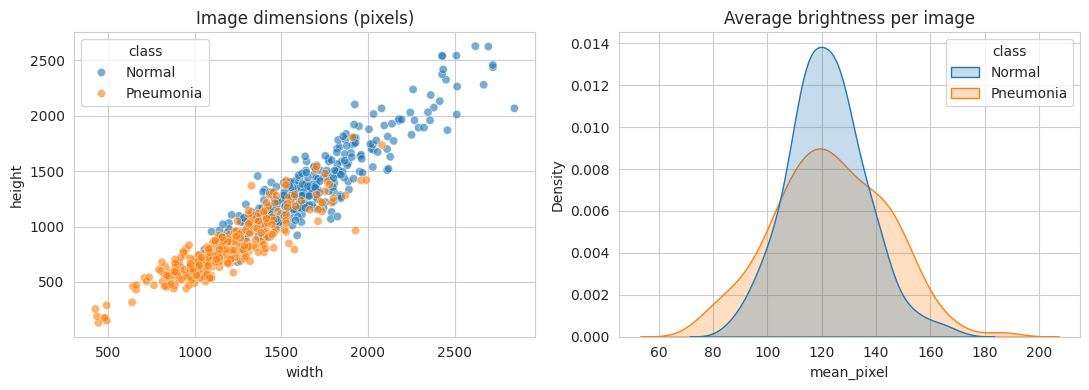

In [11]:
# Use a sample of up to 300 images per class to keep this quick
sample_df = df.groupby('label', group_keys=False).apply(lambda g: g.sample(min(len(g), 300), random_state=SEED))

info = []
for p, lab in zip(sample_df['path'], sample_df['label']):
    with Image.open(p) as im:
        w, h = im.size
        mean_pixel = np.asarray(im.convert('L')).mean()
    info.append({'width': w, 'height': h, 'mean_pixel': mean_pixel, 'class': CLASS_NAMES[lab]})
info = pd.DataFrame(info)

print(info[['width', 'height']].describe().round(0))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=info, x='width', y='height', hue='class', alpha=0.6, ax=ax[0])
ax[0].set_title('Image dimensions (pixels)')
sns.kdeplot(data=info, x='mean_pixel', hue='class', fill=True, ax=ax[1])
ax[1].set_title('Average brightness per image')
plt.tight_layout()
plt.show()

**Insight:** Image sizes vary a lot, so every image must be resized to one fixed size for the neural network. The brightness curves show how much the two classes overlap, so brightness alone cannot separate them and the model needs to learn actual lung patterns.

# **Data Preprocessing**

**What this section does:**
1. **Stratified split:** 70% train, 15% validation, 15% test. *Stratified* keeps the Normal:Pneumonia ratio the same in all three. The dataset's own folder split (if any) is merged and re-split so all three parts follow one consistent rule.
2. **Class weights:** The smaller class gets a larger weight in the loss so the model cannot ignore it.
3. **Input pipeline (`tf.data`):** Reads each image from disk, converts it to 3 channels, resizes it and batches it. Reading from disk batch by batch keeps memory usage low.
4. **Data augmentation:** Small random flips, rotations, zooms and contrast changes, applied **only during training**, make the model more robust and reduce overfitting.
5. **Scaling:** Each model scales pixel values itself (inside the model) so the same pipeline can feed both models.

In [12]:
# 70 / 15 / 15 stratified split
X_train, X_temp, y_train, y_temp = train_test_split(
    df['path'].values, df['label'].values, test_size=0.30, stratify=df['label'].values, random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED)

print(f'Train: {len(X_train)} | Validation: {len(X_val)} | Test: {len(X_test)}')
for name, y in [('Train', y_train), ('Validation', y_val), ('Test', y_test)]:
    print(f'{name:<11} Normal: {(y == 0).sum():>5}   Pneumonia: {(y == 1).sum():>5}')

Train: 4099 | Validation: 878 | Test: 879
Train       Normal:  1108   Pneumonia:  2991
Validation  Normal:   237   Pneumonia:   641
Test        Normal:   238   Pneumonia:   641


In [13]:
# Class weights (the minority class gets a bigger weight)
w = compute_class_weight('balanced', classes=np.array([0, 1]), y=y_train)
class_weight = {0: float(w[0]), 1: float(w[1])}
print('Class weights:', {CLASS_NAMES[k]: round(v, 3) for k, v in class_weight.items()})

Class weights: {'Normal': 1.85, 'Pneumonia': 0.685}


In [14]:
def load_image(path, label):
    # Read file -> 3-channel image -> resize. Pixel values stay in 0-255 (models rescale internally).
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    return img, tf.cast(label, tf.float32)

def make_dataset(paths, labels, training):
    ds = tf.data.Dataset.from_tensor_slices((list(paths), list(labels)))
    if training:
        ds = ds.shuffle(len(paths), seed=SEED)       # shuffle only the training data
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

train_ds = make_dataset(X_train, y_train, training=True)
val_ds   = make_dataset(X_val,   y_val,   training=False)
test_ds  = make_dataset(X_test,  y_test,  training=False)   # not shuffled, so order matches y_test

# Augmentation layers (active only while training)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name='augmentation')

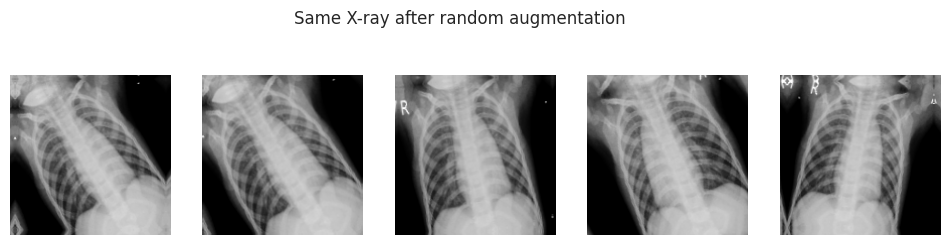

In [15]:
# Preview what augmentation does to one training image
imgs, _ = next(iter(train_ds))
plt.figure(figsize=(12, 3))
for i in range(5):
    aug = data_augmentation(tf.expand_dims(imgs[0], 0), training=True)[0]
    plt.subplot(1, 5, i + 1)
    plt.imshow(tf.cast(aug, tf.uint8))
    plt.axis('off')
plt.suptitle('Same X-ray after random augmentation')
plt.show()

# **Helper Functions**

**What this section does:** Defines reusable functions used for both models so that every model is trained and judged in exactly the same way:
- `get_callbacks`: **EarlyStopping** (stop when validation loss stops improving and keep the best weights), **ReduceLROnPlateau** (lower the learning rate when progress stalls) and **ModelCheckpoint** (save the best model).
- `plot_history`: training vs validation accuracy and loss curves. A growing gap between them means overfitting.
- `evaluate_model`: scores a model on the **unseen test set** and records accuracy, precision, recall, F1 and ROC-AUC.

**Which metric matters most?** In medical screening, missing a sick patient (a *false negative*) is worse than a false alarm. So **recall for the Pneumonia class** is the key metric, balanced against precision through the F1 score.

In [16]:
METRICS = ['accuracy',
           tf.keras.metrics.Precision(name='precision'),
           tf.keras.metrics.Recall(name='recall'),
           tf.keras.metrics.AUC(name='auc')]

def get_callbacks(ckpt_name):
    return [
        callbacks.EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
        callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=2, min_lr=1e-7),
        callbacks.ModelCheckpoint(os.path.join(OUTPUT_DIR, ckpt_name), monitor='val_loss', save_best_only=True),
    ]

def plot_history(history, title):
    h = history.history
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h['accuracy'], label='Train'); ax[0].plot(h['val_accuracy'], label='Validation')
    ax[0].set_title(f'{title} - Accuracy'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(h['loss'], label='Train'); ax[1].plot(h['val_loss'], label='Validation')
    ax[1].set_title(f'{title} - Loss'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    plt.tight_layout()
    plt.show()

results = {}      # name -> metric dict
roc_data = {}     # name -> (fpr, tpr, auc)

def evaluate_model(model, name):
    y_prob = model.predict(test_ds, verbose=0).ravel()
    y_pred = (y_prob >= 0.5).astype(int)

    res = {'Accuracy':  accuracy_score(y_test, y_pred),
           'Precision': precision_score(y_test, y_pred),
           'Recall':    recall_score(y_test, y_pred),
           'F1':        f1_score(y_test, y_pred),
           'ROC-AUC':   roc_auc_score(y_test, y_prob)}
    results[name] = res
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, res['ROC-AUC'])

    print(f'===== {name}: TEST SET RESULTS =====')
    print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(f'Confusion Matrix - {name}')
    plt.tight_layout()
    plt.show()

# **Model 1: CNN from Scratch**

**What this section does:** Builds a Convolutional Neural Network (CNN) from scratch.

**Why a CNN:** Convolution filters slide over the image and learn visual patterns (edges first, then textures and shapes). This is why CNNs are the standard choice for image classification.

**Architecture:**
- Augmentation, then pixel scaling to the 0-1 range.
- **4 convolution blocks:** Conv2D (3x3, ReLU) -> BatchNormalization -> MaxPooling. The filters grow 32 -> 64 -> 128 -> 128 so the network learns more complex patterns deeper in.
- **Global Average Pooling** instead of a huge Flatten layer, which means fewer parameters and less overfitting.
- Dense(128) + **Dropout(0.5)** to regularise.
- **1 sigmoid output neuron:** the probability that the X-ray shows Pneumonia (above 0.5 means Pneumonia).
- **Loss:** binary cross-entropy. **Optimizer:** Adam.

In [17]:
def build_cnn():
    inputs = layers.Input(shape=(*IMG_SIZE, 3))
    x = data_augmentation(inputs)
    x = layers.Rescaling(1. / 255)(x)
    for filters in (32, 64, 128, 128):
        x = layers.Conv2D(filters, (3, 3), padding='same', activation='relu')(x)
        x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D((2, 2))(x)
    x = layers.Dropout(0.3)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(128, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid')(x)
    model = models.Model(inputs, outputs, name='cnn_from_scratch')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=METRICS)
    return model

cnn_model = build_cnn()
cnn_model.summary()

Model: "cnn_from_scratch"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 160, 160, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 80, 80, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 40, 40, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 20, 20, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,881 (1011.25 KB)

 Trainable params: 258,177 (1008.50 KB)

 Non-trainable params: 704 (2.75 KB)

In [ ]:
history_cnn = cnn_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_CNN,
                            class_weight=class_weight, callbacks=get_callbacks('cnn_best.keras'))
plot_history(history_cnn, 'CNN from scratch')

In [ ]:
evaluate_model(cnn_model, 'CNN from scratch')

# **Model 2: Transfer Learning (MobileNetV2)**

**What this section does:** Uses **MobileNetV2**, a network already trained on millions of everyday images (ImageNet). It has already learned general visual features such as edges, textures and shapes, and we reuse them for X-rays.

**Why transfer learning:** Medical datasets are usually small. Starting from pre-trained knowledge generally gives higher accuracy with less data and less training time than training from scratch.

**Two stages:**
1. **Stage 1 (feature extraction):** Freeze the pre-trained layers and train only our new classification head.
2. **Stage 2 (fine-tuning):** Unfreeze the last 30 layers of MobileNetV2 and train them with a very small learning rate (1e-5) to adapt them gently to X-ray images without destroying what they learnt.

MobileNetV2 expects inputs scaled to the range -1 to 1, which the `Rescaling` layer handles.

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/8
129/129 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.8039 - auc: 0.8962 - loss: 0.4054 - precision: 0.9240 - recall: 0.7967 - val_accuracy: 0.8554 - val_auc: 0.9556 - val_loss: 0.3433 - val_precision: 0.9777 - val_recall: 0.8206 - learning_rate: 0.0010
Epoch 2/8
129/129 ━━━━━━━━━━━━━━━━━━━━ 179s 1s/step - accuracy: 0.8897 - auc: 0.9570 - loss: 0.2655 - precision: 0.9611 - recall: 0.8847 - val_accuracy: 0.8030 - val_auc: 0.9637 - val_loss: 0.4479 - val_precision: 0.9916 - val_recall: 0.7363 - learning_rate: 0.0010
Epoch 3/8
129/129 ━━━━━━━━━━━━━━━━━━━━ 182s 1s/step - accuracy: 0.9002 - auc: 0.9653 - loss: 0.2380 - precision: 0.9674 - recall: 0.8933 - val_accuracy: 0.8383 - val_auc: 0.9680 - val_loss: 0.3651 - val_precision: 0.9864 - val_recall: 0.7894 - learning_rate: 0.0010
Epoch 4/8
129/129 ━━━━━━━━━━━━━━━━━━━━ 186s 1s/step - accuracy: 0.9041 - auc: 0.9672 - loss: 0.2309 - precision: 0.9659 - recall: 0.9004 - val_accuracy: 

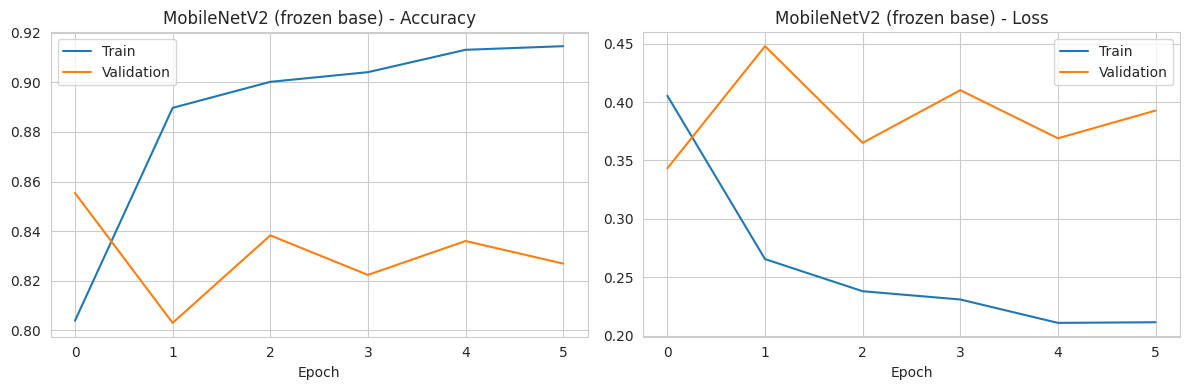

In [18]:
base_model = tf.keras.applications.MobileNetV2(input_shape=(*IMG_SIZE, 3), include_top=False, weights='imagenet')
base_model.trainable = False          # Stage 1: freeze

inputs = layers.Input(shape=(*IMG_SIZE, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1. / 127.5, offset=-1)(x)       # 0-255  ->  -1 to 1
x = base_model(x, training=False)                     # keep BatchNorm layers in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation='sigmoid')(x)
tl_model = models.Model(inputs, outputs, name='mobilenetv2_transfer')
tl_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy', metrics=METRICS)

history_tl = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_TL,
                          class_weight=class_weight, callbacks=get_callbacks('tl_best.keras'))
plot_history(history_tl, 'MobileNetV2 (frozen base)')

===== MobileNetV2 (frozen): TEST SET RESULTS =====
              precision    recall  f1-score   support

      Normal     0.6427    0.9370    0.7624       238
   Pneumonia     0.9718    0.8066    0.8815       641

    accuracy                         0.8419       879
   macro avg     0.8072    0.8718    0.8219       879
weighted avg     0.8827    0.8419    0.8493       879



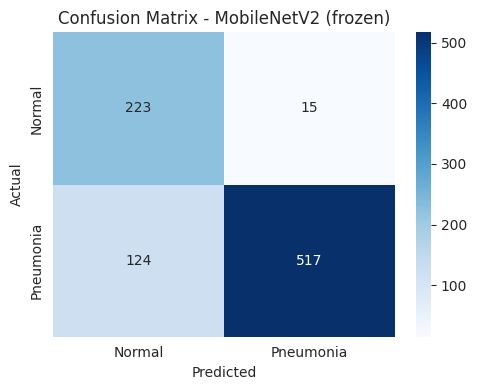

In [19]:
evaluate_model(tl_model, 'MobileNetV2 (frozen)')

### Stage 2: Fine-tuning
Unfreeze the last 30 layers of the base network and continue training with a much smaller learning rate.

Epoch 1/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 241s 2s/step - accuracy: 0.8827 - auc: 0.9482 - loss: 0.2896 - precision: 0.9475 - recall: 0.8742 - val_accuracy: 0.8793 - val_auc: 0.9653 - val_loss: 0.2762 - val_precision: 0.9735 - val_recall: 0.8580 - learning_rate: 1.0000e-05
Epoch 2/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 204s 2s/step - accuracy: 0.9049 - auc: 0.9714 - loss: 0.2168 - precision: 0.9693 - recall: 0.8980 - val_accuracy: 0.8759 - val_auc: 0.9714 - val_loss: 0.2883 - val_precision: 0.9819 - val_recall: 0.8456 - learning_rate: 1.0000e-05
Epoch 3/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 206s 2s/step - accuracy: 0.9173 - auc: 0.9745 - loss: 0.2020 - precision: 0.9716 - recall: 0.9134 - val_accuracy: 0.8759 - val_auc: 0.9742 - val_loss: 0.2834 - val_precision: 0.9819 - val_recall: 0.8456 - learning_rate: 1.0000e-05
Epoch 4/5
129/129 ━━━━━━━━━━━━━━━━━━━━ 220s 2s/step - accuracy: 0.9227 - auc: 0.9779 - loss: 0.1888 - precision: 0.9772 - recall: 0.9154 - val_accuracy: 0.8713 - val_auc: 0.9754 - val_loss: 

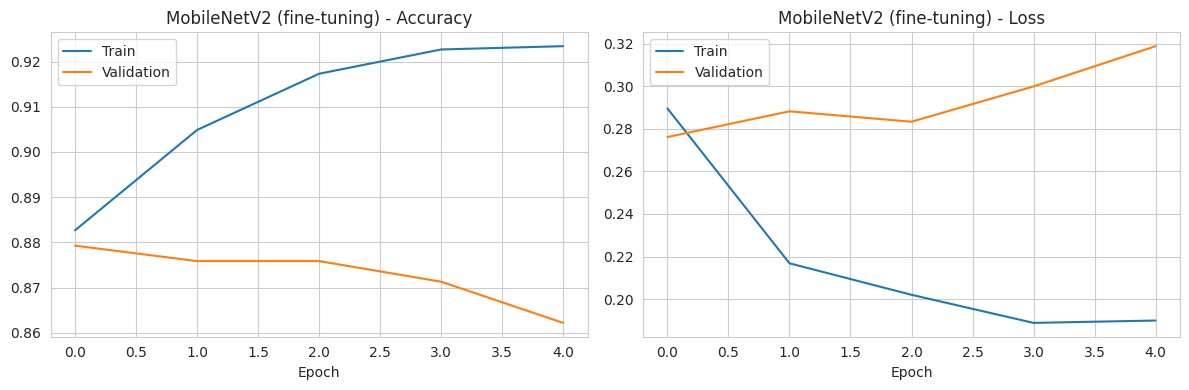

In [20]:
base_model.trainable = True
for layer in base_model.layers[:-30]:      # keep everything except the last 30 layers frozen
    layer.trainable = False

tl_model.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss='binary_crossentropy', metrics=METRICS)

history_ft = tl_model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FT,
                          class_weight=class_weight, callbacks=get_callbacks('tl_finetuned_best.keras'))
plot_history(history_ft, 'MobileNetV2 (fine-tuning)')

===== MobileNetV2 (fine-tuned): TEST SET RESULTS =====
              precision    recall  f1-score   support

      Normal     0.7055    0.9160    0.7971       238
   Pneumonia     0.9649    0.8580    0.9083       641

    accuracy                         0.8737       879
   macro avg     0.8352    0.8870    0.8527       879
weighted avg     0.8947    0.8737    0.8782       879



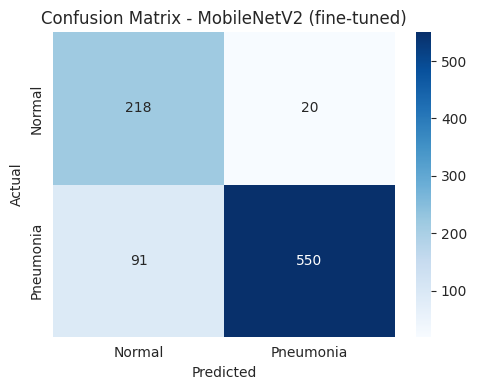

In [21]:
evaluate_model(tl_model, 'MobileNetV2 (fine-tuned)')

# **Model Comparison**

**What this section does:** Puts all models side by side on the same unseen test set, and overlays their ROC curves. A better ROC curve hugs the top-left corner (high true positive rate with low false positive rate); the diagonal line is random guessing.

,Accuracy,Precision,Recall,F1,ROC-AUC
MobileNetV2 (fine-tuned),0.8737,0.9649,0.8580,0.9083,0.9623
MobileNetV2 (frozen),0.8419,0.9718,0.8066,0.8815,0.9537


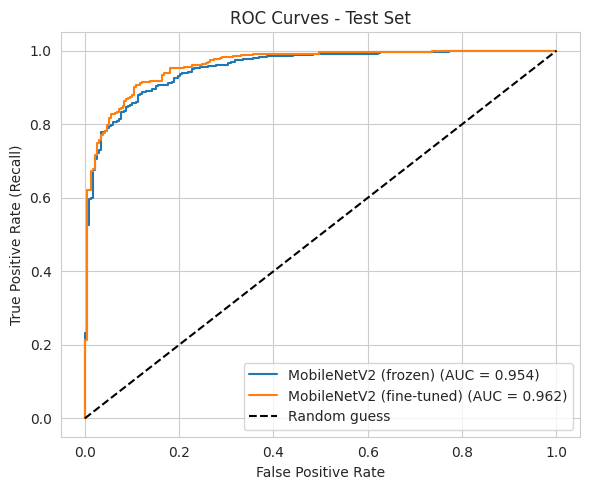

In [22]:
results_df = pd.DataFrame(results).T.round(4)
display(results_df.sort_values('F1', ascending=False))

plt.figure(figsize=(6, 5))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random guess')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate (Recall)')
plt.title('ROC Curves - Test Set'); plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

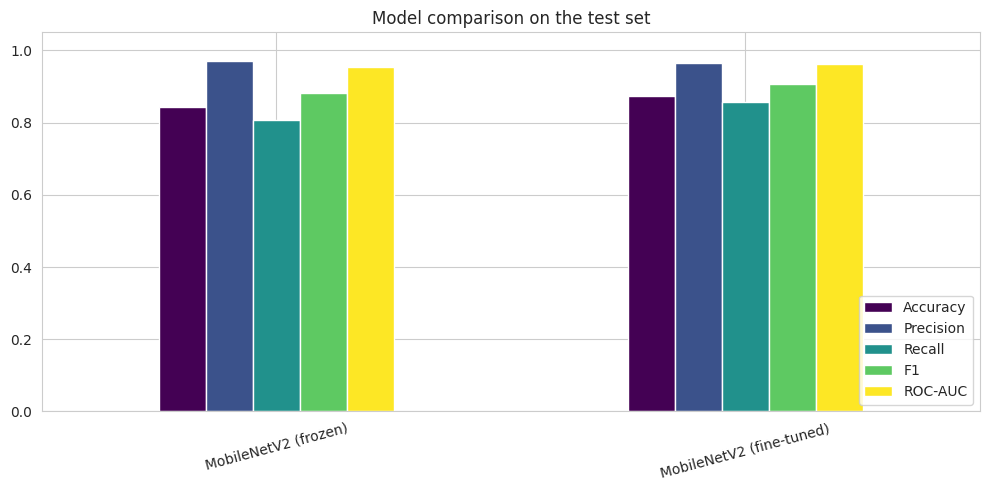

In [23]:
results_df[['Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']].plot(kind='bar', figsize=(10, 5), colormap='viridis')
plt.title('Model comparison on the test set')
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

# **Final Model Selection and Save**

**What this section does:** Picks the model with the best **F1 score** on the test set (it balances recall and precision, so it does not reward a model that simply labels everything as Pneumonia). The chosen model is saved to disk so it can be reused without retraining.

**Note:** For a clinical setting you might choose differently, for example the model with the highest recall, accepting more false alarms in exchange for fewer missed cases.

===== CNN from scratch: TEST SET RESULTS =====
              precision    recall  f1-score   support

      Normal     0.2708    1.0000    0.4261       238
   Pneumonia     0.0000    0.0000    0.0000       641

    accuracy                         0.2708       879
   macro avg     0.1354    0.5000    0.2131       879
weighted avg     0.0733    0.2708    0.1154       879



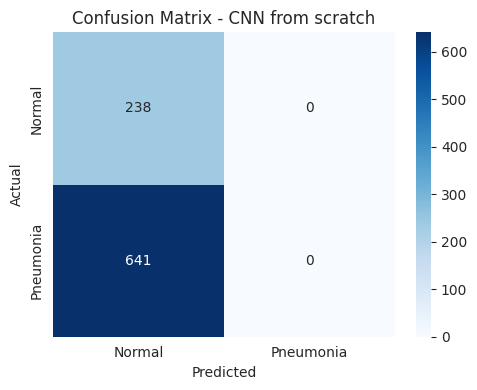

Best model : MobileNetV2 (fine-tuned)
Accuracy     0.8737
Precision    0.9649
Recall       0.8580
F1           0.9083
ROC-AUC      0.9623
Name: MobileNetV2 (fine-tuned), dtype: float64

Saved to  : outputs/best_pneumonia_model.keras


In [25]:
trained_models = {'CNN from scratch': cnn_model, 'MobileNetV2 (fine-tuned)': tl_model}

# Evaluate any model whose results are missing
for name, m in trained_models.items():
    if name not in results:
        evaluate_model(m, name)
results_df = pd.DataFrame(results).T.round(4)

candidates = results_df.loc[list(trained_models.keys())]
best_name = candidates['F1'].idxmax()
best_model = trained_models[best_name]

print('Best model :', best_name)
print(candidates.loc[best_name].round(4))

best_model.save(os.path.join(OUTPUT_DIR, 'best_pneumonia_model.keras'))
print('\nSaved to  :', os.path.join(OUTPUT_DIR, 'best_pneumonia_model.keras'))

# **Predict on a New X-ray**

**What this section does:** Defines `predict_xray()`, which takes the path of any chest X-ray image and returns the predicted class and the model's confidence. It is demonstrated on a few random test images, and it shows how to reload the saved model later.

**Disclaimer:** This is a learning project, not a medical device. Real diagnosis must be made by a qualified doctor.

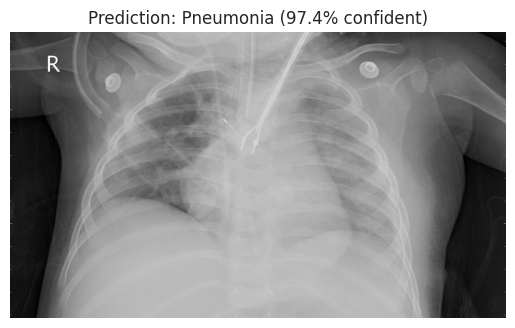

Actual: Pneumonia  Predicted: Pneumonia  (97.4%)


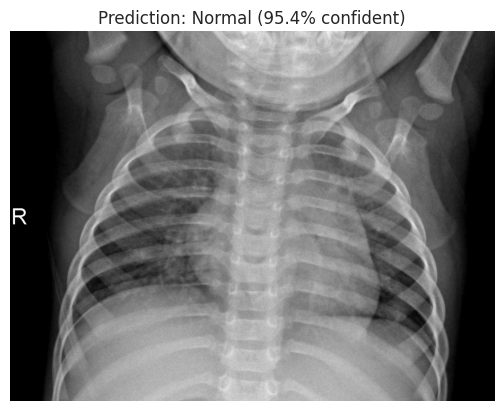

Actual: Normal     Predicted: Normal     (95.4%)


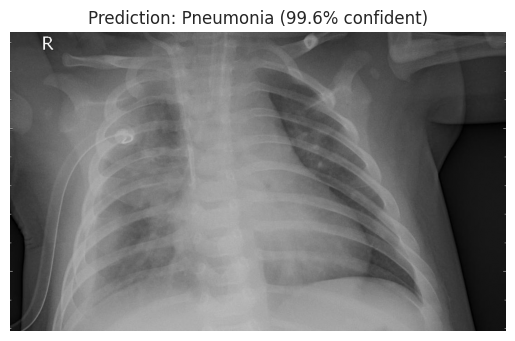

Actual: Pneumonia  Predicted: Pneumonia  (99.6%)


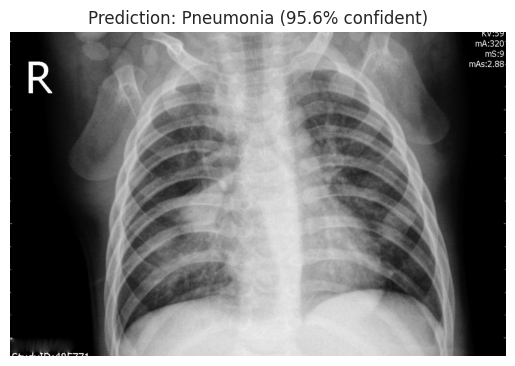

Actual: Pneumonia  Predicted: Pneumonia  (95.6%)


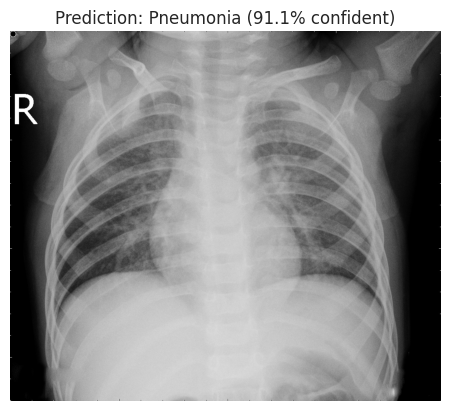

Actual: Normal     Predicted: Pneumonia  (91.1%)


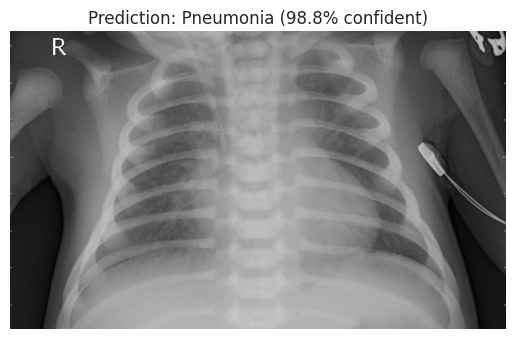

Actual: Pneumonia  Predicted: Pneumonia  (98.8%)


In [26]:
def predict_xray(model, image_path, show=True):
    img, _ = load_image(image_path, 0)                       # same preprocessing as training
    prob = float(model.predict(tf.expand_dims(img, 0), verbose=0)[0][0])
    label = CLASS_NAMES[int(prob >= 0.5)]
    confidence = prob if prob >= 0.5 else 1 - prob
    if show:
        plt.imshow(Image.open(image_path).convert('L'), cmap='gray')
        plt.title(f'Prediction: {label} ({confidence * 100:.1f}% confident)')
        plt.axis('off')
        plt.show()
    return label, confidence

# Try it on 6 random test images
true_label = dict(zip(X_test, y_test))
for p in random.sample(list(X_test), 6):
    label, conf = predict_xray(best_model, p)
    print(f'Actual: {CLASS_NAMES[true_label[p]]:<10} Predicted: {label:<10} ({conf * 100:.1f}%)')

In [27]:
# How to load the saved model later (for example in another notebook or app):
# loaded = tf.keras.models.load_model('outputs/best_pneumonia_model.keras')
# predict_xray(loaded, 'path/to/some_xray.jpg')

# **Final Summary**

The cell below prints a summary from the real results of your run, so the numbers always match the notebook outputs.

In [28]:
best = results_df.loc[best_name]
print('=' * 60)
print('   FINAL SUMMARY - Pneumonia Chest X-ray Classification')
print('=' * 60)
print(f'Total images      : {len(df)}  (Normal: {(df.label == 0).sum()}, Pneumonia: {(df.label == 1).sum()})')
print(f'Split             : Train {len(X_train)} | Validation {len(X_val)} | Test {len(X_test)}')
print(f'Models compared   : {", ".join(results_df.index)}')
print(f'Best model        : {best_name}')
print(f'  Accuracy        : {best["Accuracy"]:.4f}')
print(f'  Recall (Pneum.) : {best["Recall"]:.4f}')
print(f'  Precision       : {best["Precision"]:.4f}')
print(f'  F1 score        : {best["F1"]:.4f}')
print(f'  ROC-AUC         : {best["ROC-AUC"]:.4f}')
print('=' * 60)

   FINAL SUMMARY - Pneumonia Chest X-ray Classification
Total images      : 5856  (Normal: 1583, Pneumonia: 4273)
Split             : Train 4099 | Validation 878 | Test 879
Models compared   : MobileNetV2 (frozen), MobileNetV2 (fine-tuned), CNN from scratch
Best model        : MobileNetV2 (fine-tuned)
  Accuracy        : 0.8737
  Recall (Pneum.) : 0.8580
  Precision       : 0.9649
  F1 score        : 0.9083
  ROC-AUC         : 0.9623


# **Conclusion**
- Built a complete pipeline for detecting Pneumonia from chest X-rays: data download, labelling, EDA, stratified split, augmentation, training, evaluation and saving.
- Trained and compared **a CNN built from scratch** and **a transfer-learning model (MobileNetV2, frozen and fine-tuned)** on the same unseen test set.
- Used class weights and recall / precision / F1 / ROC-AUC (not just accuracy) because the classes can be imbalanced and missing a Pneumonia case is costly.
- Selected the best model by F1 score, saved it (`outputs/best_pneumonia_model.keras`) and provided `predict_xray()` for predicting on new X-rays.
- Transfer learning normally performs better than a scratch CNN on small medical image datasets; check the comparison table above for the result on your run.

# **Challenges Faced**
1. **Class imbalance:** One class can be much larger than the other, so accuracy alone is misleading. Solved with class weights and by reporting recall, precision, F1 and ROC-AUC.
2. **Different image sizes:** The X-rays come in many resolutions, so all images were resized to 160x160 and converted to a consistent 3-channel format.
3. **Overfitting risk:** Medical image datasets are small relative to the model size. Reduced with augmentation, dropout, batch normalisation, global average pooling and early stopping.
4. **Folder-based labels:** Labels come from folder names, so labelling was made flexible and printed for verification before training.
5. **Memory usage:** Loading all images into memory is wasteful, so a `tf.data` pipeline reads and preprocesses images batch by batch.
6. **Training time:** CNN training is slow on CPU. Solved by using a GPU (Google Colab) and callbacks (early stopping, learning-rate reduction) that avoid wasted epochs.

# **Future Enhancements**
- **Bigger pre-trained models:** Try DenseNet121 or ResNet50 (CheXNet used DenseNet121 for chest X-rays) and compare.
- **Hyperparameter tuning:** Tune learning rate, dropout, number of unfrozen layers and image size with KerasTuner or Optuna.
- **Threshold tuning:** Choose the decision threshold from the ROC / precision-recall curve to reach a target recall (for example 98%) for screening use.
- **Explainability:** Add **Grad-CAM** heatmaps showing which lung regions drove each prediction, which builds trust with doctors.
- **Cross-validation and external validation:** Test on X-rays from other hospitals to check that the model generalises.
- **More classes:** Extend to bacterial vs viral pneumonia, or other chest conditions.
- **Deployment:** Wrap the saved model in a Streamlit or FastAPI app where a user uploads an X-ray and gets a prediction.
- **Monitoring:** Track performance over time and retrain as new data arrives.